In [1]:
from src.gradient import SLMphaseRetrievalCG,build_input,build_pbb_target,SLMphaseRetrievalCG3D
from src.utils import phase_pbb_10,bottle_beam_phase
import torch
import matplotlib.pyplot as plt
import numpy as np
%load_ext autoreload
%autoreload 2

/Users/apple/anaconda3/envs/slm/lib/python3.13/site-packages/slmsuite/holography/algorithms/_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [23]:
import matplotlib.pyplot as plt

def plot_cropped_sections(A_t, pad_factor):
    # compute indices & crops
    nz, ny, nx = A_t.shape
    z_center = (nz ) // 2

    z0    = z_center
    x_idx = 512 * pad_factor
    y_idx = 640 * pad_factor

    xy = A_t[z0,
             502 * pad_factor : 522 * pad_factor,
             630 * pad_factor : 650 * pad_factor]

    yz = A_t[:,
             x_idx,
             630 * pad_factor : 650 * pad_factor]

    xz = A_t[:, 
             502 * pad_factor : 522 * pad_factor,
             y_idx]

    # plot all three in one row
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # XY @ Z=0
    im0 = axes[0].imshow(xy, aspect='auto', origin='lower', cmap='inferno')
    axes[0].set_title(f'XY @ Z={z0}')
    axes[0].set_xlabel('X (cropped)')
    axes[0].set_ylabel('Y (cropped)')
    fig.colorbar(im0, ax=axes[0], label='Intensity')

    # YZ @ X=middle
    im1 = axes[1].imshow(yz, aspect='auto', origin='lower', cmap='inferno')
    axes[1].set_title(f'YZ @ X={x_idx}')
    axes[1].set_xlabel('Z')
    axes[1].set_ylabel('Y')
    fig.colorbar(im1, ax=axes[1], label='Intensity')

    # XZ @ Y=middle
    im2 = axes[2].imshow(xz, aspect='auto', origin='lower', cmap='inferno')
    axes[2].set_title(f'XZ @ Y={y_idx}')
    axes[2].set_xlabel('X (cropped)')
    axes[2].set_ylabel('Z')
    fig.colorbar(im2, ax=axes[2], label='Intensity')

    plt.tight_layout()
    plt.show()


In [24]:
pad_factor = 4
A_input = build_input()
A_target = build_pbb_target(pad_factor=pad_factor,n=6)
m3d = SLMphaseRetrievalCG3D(A_in = A_input,A_t = None,pad_factor=pad_factor)

In [25]:
from src.plots import bb


def bottle_beam_phase():
    ro = 210
    return np.array([[np.pi if ((i-512)**2 + (j-640)**2) <= ro**2 else 0 for j in range(1280)] for i in range(1024)])
bb_phase = torch.tensor(bottle_beam_phase())

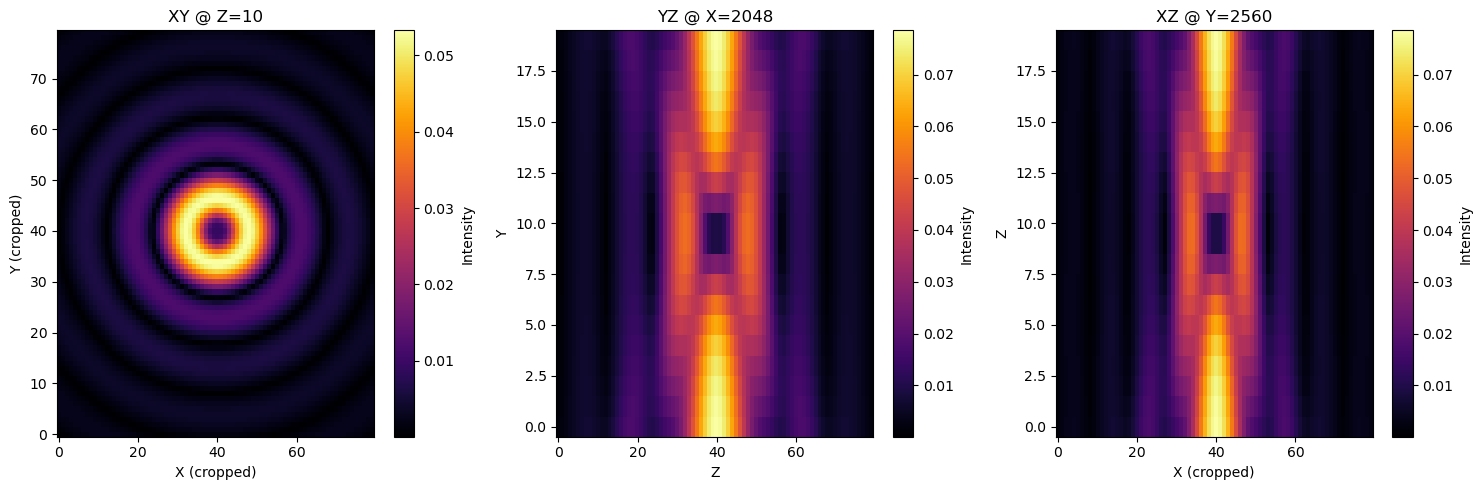

In [26]:
targ = m3d.build_target_from_phase(bb_phase)
plot_cropped_sections(m3d.A_t, pad_factor=m3d.pad_factor)

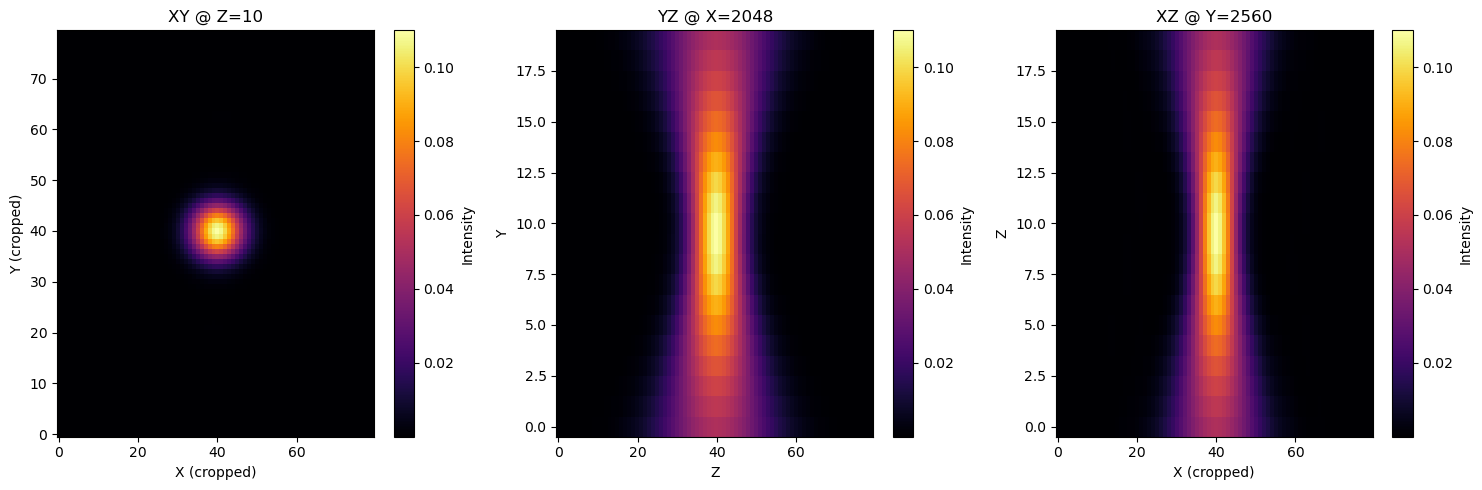

In [42]:
shape = bb_phase.shape
N = np.prod(shape)

vals = np.concatenate([np.zeros(N//10), np.full(N - N//10, np.pi)])
np.random.shuffle(vals)
rand_phase = vals.reshape(shape)
targ2 = m3d.build_target_from_phase(torch.tensor(rand_phase))
plot_cropped_sections(m3d.A_t, pad_factor=m3d.pad_factor)

In [30]:
targ.shape

torch.Size([20, 4096, 5120])

In [40]:
(targ[10]**2).sum()

tensor(1.0000, dtype=torch.float64)

In [39]:
(targ2[10]**2).sum()

tensor(1.0000, dtype=torch.float64)

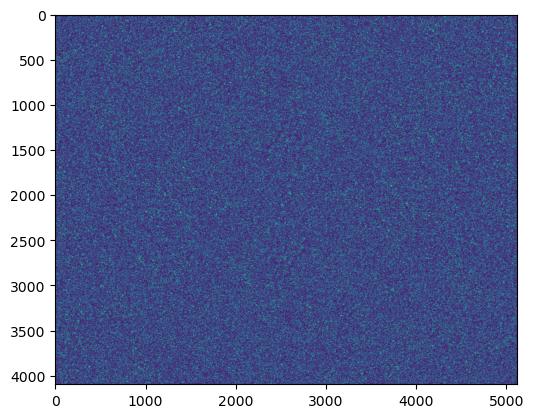

In [34]:
plt.imshow(targ2[10])